# 1 · Small-system tests and pyLIQTR logical resources

This notebook uses the six Python modules in this folder. It tests **one Hamiltonian**, runs **the reaction segment**, and counts the **actual sampled W circuits with pyLIQTR**. The second notebook uses `rxn.small_config()` and the same seed for Rottnest physical estimates.

`Hamiltonian.py → filter.py → contextual.py / low_trotter.py → one_ham.py → entire_rxn_with_circuit.py`

The default two-frame H₃ example is a fast pipeline test. A separate **chemical-accuracy convergence section** below runs full settings for one geometry from HF. Its small Fourier cutoff and few updates are **not converged chemistry**; an individual sampled trajectory need not cool monotonically. No CSV, pickle, JSON or image output files are written. Figures and tables stay in memory and display below.

In [1]:
from pathlib import Path
from collections import Counter
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
ROOT = next(p for p in (Path.cwd(), Path.cwd()/"newer")
            if (p/"entire_rxn_with_circuit.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import cirq
import matplotlib.pyplot as plt
from IPython.display import display
import entire_rxn_with_circuit as rxn
import one_ham, low_trotter, contextual
from filter import Jump, make_jumps
CONFIG = rxn.small_config()
assert CONFIG["save_outputs"] == "none"
print("Python:", sys.executable)
display(pd.Series({k:CONFIG[k] for k in ["xyz_trajectory", "geometry_start", "geometry_stop",
    "filter_K", "reps_per_W", "N_applications", "tau_W", "hamiltonian_simulation",
    "trotter_steps_H", "final_rank", "w_convention", "save_outputs"]}, name="shared settings"))

Python: /Users/soumyasarkar/Desktop/rottnest/rottnest_venv/bin/python


xyz_trajectory            H3_rxn_trj.xyz
geometry_start                       111
geometry_stop                        113
filter_K                               2
reps_per_W                             2
N_applications                         4
tau_W                                0.1
hamiltonian_simulation          low_rank
trotter_steps_H                        2
final_rank                             4
w_convention                    centered
save_outputs                        none
Name: shared settings, dtype: object

## One Hamiltonian
The ancilla is reset after every W. `sampled_circuit` samples a coupling and applies its cached, Cirq-equivalent Kraus channel. `direct_circuit` simulates the same selected circuits with Cirq. `averaged_matrix` applies the weighted average over **all** couplings at every step; it is not expected to equal a single sampled trajectory.

In [2]:
one_config = dict(CONFIG, geometry_stop=CONFIG["geometry_start"]+1)
single = rxn.run_reaction(one_config)
g = single["geometries"][0]
factory = g["factory"]
H_eff = g["reduction"].hamiltonian
rho_in = g["initial_rho"]
sequence = g["chain"]["sequence"]
display(pd.DataFrame(single["summary"]))
display(pd.Series(g["diagnostics"]["alignment"], name="orbital alignment"))
print("Sampled jump indices:", sequence)
print("Filter L, T:", g["filter"]["L"], g["filter"]["T_filter"])
print("Unique W blocks / applications:", len(factory.circuits), len(sequence))

Frame 111: 6 qubits, 4 W, 4 cached blocks, energy=-1.5266594369834952, 0.17 s


,hamiltonian_index,geometry_index,initial_energy,final_energy,target_energy,final_energy_error,initial_final_overlap,sector_weight,original_qubits,retained_qubits,...,filter_L,T_filter,trotter_steps,chemistry_seconds,propagator_build_seconds,circuit_build_seconds,kraus_build_seconds,channel_apply_seconds,energy_seconds,total_seconds
0,111,0,-1.531077,-1.526659,-1.571005,0.044346,0.989381,1.0,6,6,...,3.50683,0.89585,2,0.04538,0.004026,0.005267,0.045456,0.00018,0.000067,0.167159


enabled              True
first_geometry       True
min_block_overlap     1.0
Name: orbital alignment, dtype: object

Sampled jump indices: [20, 23, 25, 0]
Filter L, T: 3.506829681496881 0.895849795661822
Unique W blocks / applications: 4 4


Direct Cirq vs cached sampled density matrix: 2.691e-12


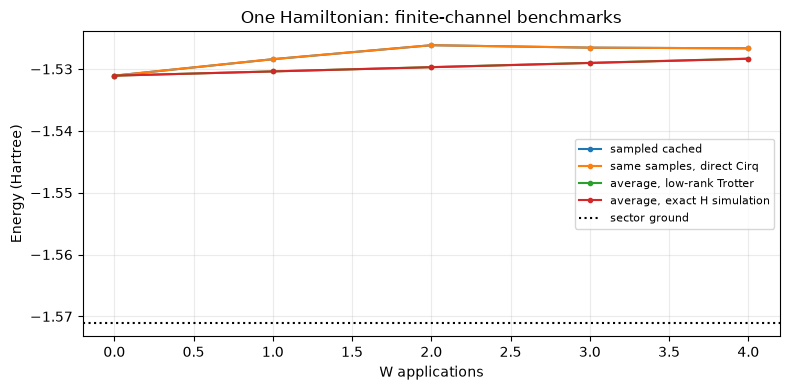

,trace,min_eigenvalue,max_hermiticity_error
sampled cached,1.0,-2.783871e-16,8.677852e-19
"same samples, direct Cirq",1.0,-6.742412e-15,9.138277e-13
"average, low-rank Trotter",1.0,-1.631913e-16,1.318989e-18
"average, exact H simulation",1.0,-5.756962e-16,8.673618e-19


In [3]:
direct = one_ham.run_chain(factory, H_eff, rho_in, applications=len(sequence),
    mode="direct_circuit", sequence=sequence, seed=CONFIG["rng_seed"])
averaged = one_ham.run_chain(factory, H_eff, rho_in, applications=len(sequence),
    mode="averaged_matrix", seed=CONFIG["rng_seed"])
difference = np.linalg.norm(direct["rho"]-g["chain"]["rho"])
assert difference < 2e-8, difference
print(f"Direct Cirq vs cached sampled density matrix: {difference:.3e}")
# Independent ideal-Hamiltonian benchmark: same finite filter, exact exp(i H T).
exact_prop = low_trotter.build_propagator(H_eff, factory.qubits,
    -g["filter"]["T_filter"], method="exact_matrix")
exact_factory = one_ham.WFactory(factory.qubits, factory.ancilla, factory.jumps,
    exact_prop, factory.filter_terms, factory.tau, factory.cutoff,
    convention=factory.convention)
exact_average = one_ham.run_chain(exact_factory, H_eff, rho_in,
    applications=len(sequence), mode="averaged_matrix", seed=CONFIG["rng_seed"])
comparisons = {"sampled cached":g["chain"], "same samples, direct Cirq":direct,
               "average, low-rank Trotter":averaged, "average, exact H simulation":exact_average}
fig,ax=plt.subplots(figsize=(8,4))
for label,run in comparisons.items():
    ax.plot([r["step"] for r in run["energies"]], [r["energy"] for r in run["energies"]],
            marker=".", label=label)
ax.axhline(single["summary"][0]["target_energy"], ls=":", color="black", label="sector ground")
ax.set(xlabel="W applications", ylabel="Energy (Hartree)", title="One Hamiltonian: finite-channel benchmarks")
ax.legend(fontsize=8);ax.grid(alpha=.25);fig.tight_layout();plt.show()
display(pd.DataFrame({name:run["diagnostics"] for name,run in comparisons.items()}).T)

### Reuse and measured timing
The cache saves classical construction/simulation work. It does **not** remove the repeated W applications from the quantum resource count. These timings are wall-clock measurements on this machine; Cirq application time excludes its one-time circuit decomposition.

,channel_apply_seconds,energy_seconds
sampled cached,0.000180,0.000067
"same samples, direct Cirq",20.969953,0.000141
"average, low-rank Trotter",0.005823,0.000078
"average, exact H simulation",0.005832,0.000065


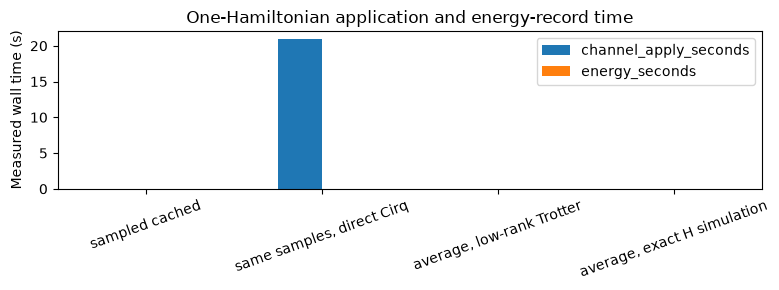

In [4]:
timing = pd.DataFrame({name:{k:v for k,v in run["timings"].items()
    if k in ("channel_apply_seconds","energy_seconds")}
    for name,run in comparisons.items()}).T
display(timing)
ax=timing.plot.bar(figsize=(8,3), rot=20)
ax.set(ylabel="Measured wall time (s)", title="One-Hamiltonian application and energy-record time")
plt.tight_layout();plt.show()

## Entire reaction segment
This calls the same driver used on HPC. Energy, energy error, cumulative-W energy, initial/final density overlap and timing plots are generated by one shared plotting function. Original trajectory indices remain on the axes. The energy includes the nuclear/core constant exactly once.

Frame 111: 6 qubits, 4 W, 4 cached blocks, energy=-1.5266594369835071, 0.14 s
Frame 112: 6 qubits, 4 W, 4 cached blocks, energy=-1.5250608155270269, 0.14 s


,hamiltonian_index,geometry_index,initial_energy,final_energy,target_energy,final_energy_error,initial_final_overlap,sector_weight,original_qubits,retained_qubits,...,filter_L,T_filter,trotter_steps,chemistry_seconds,propagator_build_seconds,circuit_build_seconds,kraus_build_seconds,channel_apply_seconds,energy_seconds,total_seconds
0,111,0,-1.531077,-1.526659,-1.571005,0.044346,0.989381,1.0,6,6,...,3.506830,0.895850,2,0.022545,0.003727,0.005086,0.043852,0.000178,0.000062,0.141564
1,112,1,-1.526587,-1.525061,-1.570990,0.045929,0.973162,1.0,6,6,...,3.507097,0.895781,2,0.020850,0.003999,0.005057,0.043747,0.000176,0.000059,0.138571


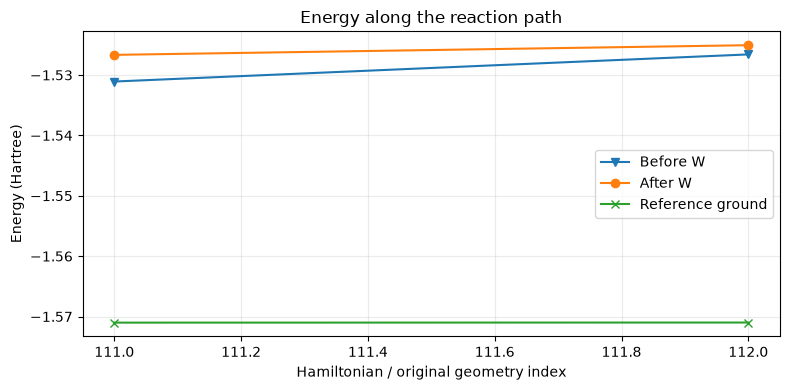

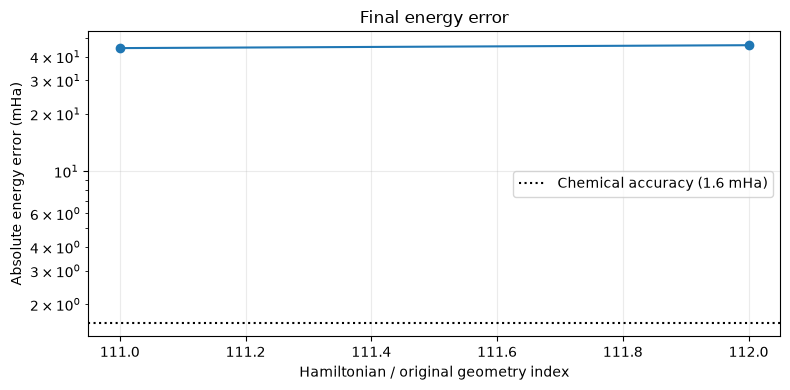

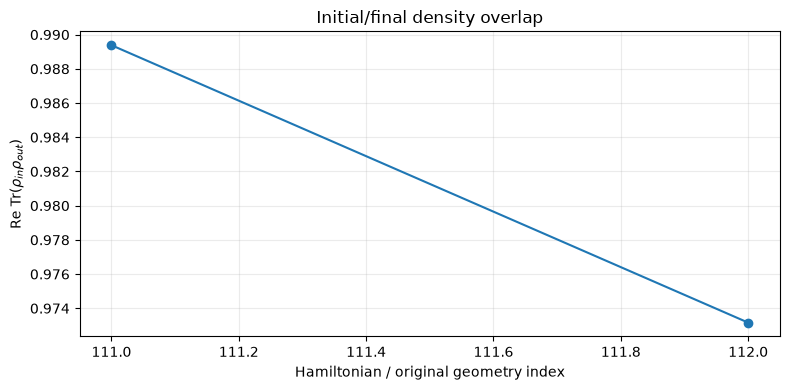

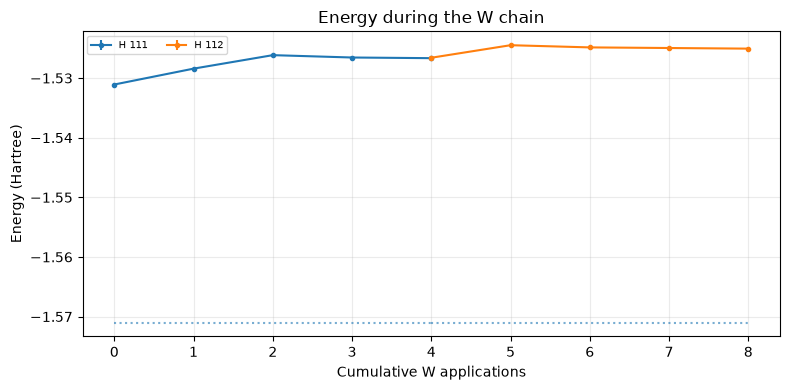

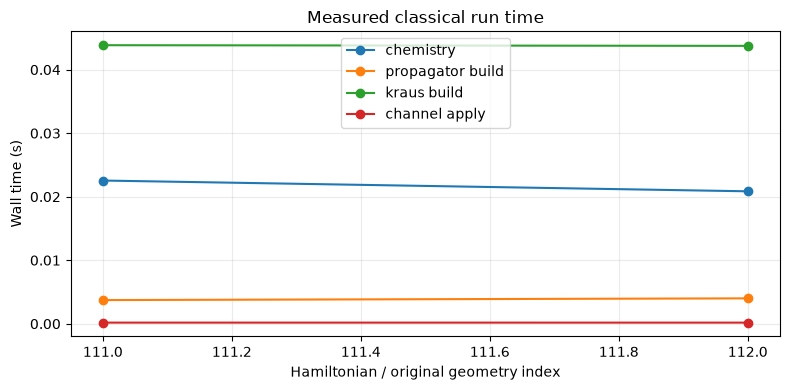

Total W applications: 8
Stored distinct W circuits: 8


In [5]:
reaction = rxn.run_reaction(CONFIG)
display(pd.DataFrame(reaction["summary"]))
figures = rxn.plot_results(reaction)
reaction_blocks = Counter()
for g in reaction["geometries"]:
    reaction_blocks.update(one_ham.selected_block_counts(g["factory"],g["chain"]["sequence"]))
print("Total W applications:", sum(reaction_blocks.values()))
print("Stored distinct W circuits:", len(reaction_blocks))

## Chemical-accuracy convergence: one geometry from Hartree–Fock
This is an actual convergence run for **trajectory frame 111**, separate from the tiny smoke tests above. The starting state is the HF determinant, about **39.93 mHa** above the exact ground energy in the original **N=3** sector. The target is not the ground energy of the rank-truncated propagator.

Use the full nominal Lanczos filter (`filter_K=500`, implemented cutoff `200`), `tau_W=0.1`, all 30 Ax/Ay JW jumps, and 1,500 sampled W applications. Keep the rank-four low-rank method and use **8 Hamiltonian-simulation steps** per filter interval. The centered norm-based interval is longer than the old width-based interval; four inner steps left a borderline error floor. Increasing the inner resolution changes the numerical approximation, not the target Hamiltonian or couplings.

We record **every W update**, retain all fluctuations, and test the fixed 1.6 mHa threshold. No ground-state initialization, contextual projection, favorable-seed search or change of reference energy is used. Additional independent jump sequences are checked below.

Frame 111: 6 qubits, 1500 W, 30 cached blocks, energy=-1.5703025535442179, 2.31 s
First update below 1.6 mHa: 331
Final error (mHa): 0.7025811837053642
Maximum error over the final 500 updates (mHa): 0.9961745228750374


,hamiltonian_index,geometry_index,initial_energy,final_energy,target_energy,final_energy_error,initial_final_overlap,sector_weight,original_qubits,retained_qubits,...,filter_L,T_filter,trotter_steps,chemistry_seconds,propagator_build_seconds,circuit_build_seconds,kraus_build_seconds,channel_apply_seconds,energy_seconds,total_seconds
0,111,0,-1.531077,-1.570303,-1.571005,0.000703,0.488886,1.0,6,6,...,3.50683,0.89585,8,0.020826,0.014017,0.808238,1.307233,0.062823,0.01542,2.306497


geometry_start                 111
initial_state                   HF
filter_K                       500
reps_per_W                     200
filter_scale                  norm
w_convention              centered
tau_W                          0.1
N_applications                1500
hamiltonian_simulation    low_rank
trotter_steps_H                  8
final_rank                       4
rng_seed                       123
Name: converged configuration, dtype: object

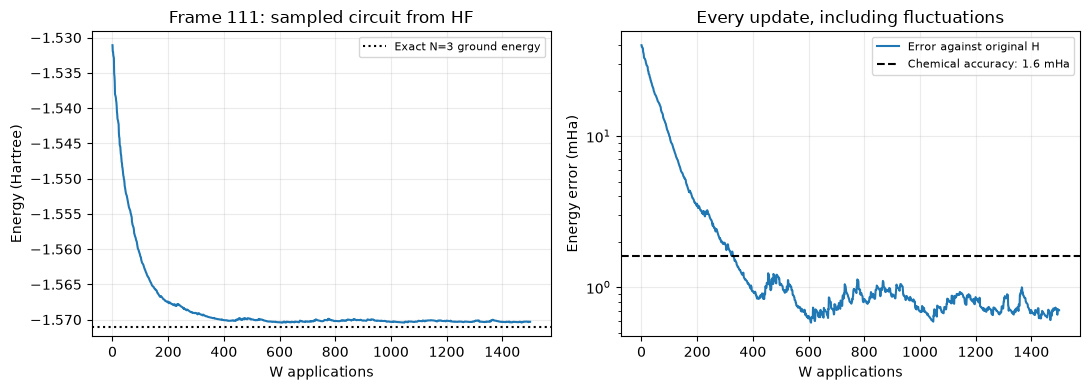

In [6]:
accuracy_config=rxn.convergence_config()
accuracy=rxn.run_reaction(accuracy_config)
ag=accuracy["geometries"][0]
reference_energy=accuracy["summary"][0]["target_energy"]
accuracy_rows=pd.DataFrame(accuracy["energy_rows"])
accuracy_rows["error_mHa"]=1000*(accuracy_rows["energy"]-reference_energy)
first_below=int(accuracy_rows.loc[accuracy_rows.error_mHa<1.6,"step"].iloc[0])
final_error=float(accuracy_rows.error_mHa.iloc[-1])
tail_max=float(accuracy_rows.error_mHa.tail(500).max())
assert final_error<1.6 and tail_max<1.6
print("First update below 1.6 mHa:",first_below)
print("Final error (mHa):",final_error)
print("Maximum error over the final 500 updates (mHa):",tail_max)
display(pd.DataFrame(accuracy["summary"]))
display(pd.Series({k:accuracy_config[k] for k in ["geometry_start","initial_state",
    "filter_K","reps_per_W","filter_scale","w_convention","tau_W","N_applications",
    "hamiltonian_simulation","trotter_steps_H","final_rank","rng_seed"]},name="converged configuration"))
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(accuracy_rows.step,accuracy_rows.energy)
axes[0].axhline(reference_energy,color="black",ls=":",label="Exact N=3 ground energy")
axes[0].set(xlabel="W applications",ylabel="Energy (Hartree)",title="Frame 111: sampled circuit from HF")
axes[0].legend(fontsize=8)
axes[1].semilogy(accuracy_rows.step,accuracy_rows.error_mHa,label="Error against original H")
axes[1].axhline(1.6,color="black",ls="--",label="Chemical accuracy: 1.6 mHa")
axes[1].set(xlabel="W applications",ylabel="Energy error (mHa)",title="Every update, including fluctuations")
axes[1].legend(fontsize=8)
for ax in axes:ax.grid(alpha=.25)
fig.tight_layout();plt.show()

In [7]:
# Independent sequences use spawned RNG streams, not shifts of the legacy seed sequence.
trials=[]
for trial,seed in enumerate(np.random.SeedSequence(20261116).spawn(5)):
    sequence=np.random.default_rng(seed).choice(len(ag["factory"].jumps),size=1500).tolist()
    trial_result=one_ham.run_chain(ag["factory"],ag["reduction"].hamiltonian,ag["initial_rho"],
        applications=1500,sequence=sequence,energy_stride=1)
    errors=np.array([row["energy"]-reference_energy for row in trial_result["energies"]])*1000
    trials.append({"trial":trial,"final_error_mHa":errors[-1],
        "max_last_500_error_mHa":errors[-500:].max(),"trace":trial_result["diagnostics"]["trace"]})
display(pd.DataFrame(trials))
assert all(row["final_error_mHa"]<1.6 for row in trials)
print("These five checks establish observed robustness here, not a universal success guarantee.")
# Logical resources for this converged circuit use the selected-jump multiplicities.
accuracy_blocks=one_ham.selected_block_counts(ag["factory"],ag["chain"]["sequence"])
accuracy_logical=one_ham.pyliqtr_resources(accuracy_blocks,circuit_precision=1e-3)
display(pd.Series(accuracy_logical,name="Converged run: pyLIQTR logical resources"))

,trial,final_error_mHa,max_last_500_error_mHa,trace
0,0,1.075577,1.830402,1.0
1,1,0.595727,1.140143,1.0
2,2,0.784263,1.367668,1.0
3,3,0.842350,1.354635,1.0
4,4,1.134418,1.144675,1.0


These five checks establish observed robustness here, not a universal success guarantee.


LogicalQubits                                                                 7
T                                                                  320936724000
Clifford                                                           643711019281
Rotations                                                            2508012000
native_T                                                             2419200000
circuit_precision                                                         0.001
per_rotation_precision                                                      0.0
unique_counted_blocks                                                      6061
scope                                                        unitary W sequence
unique_profiled_operations                                                 6215
unique_W_blocks                                                              30
W_applications                                                             1500
T_method                      pyLIQTR sy

### Old-style averaged-matrix reference
This comparison uses the earlier **width-based filter and legacy W frame**, with exact Hamiltonian propagation and the averaged channel. It is a different benchmark from one sampled trajectory; both are evaluated against the same original Hamiltonian and start from HF.

Frame 111: 6 qubits, 600 W, 30 cached blocks, energy=-1.5704289003398773, 3.40 s


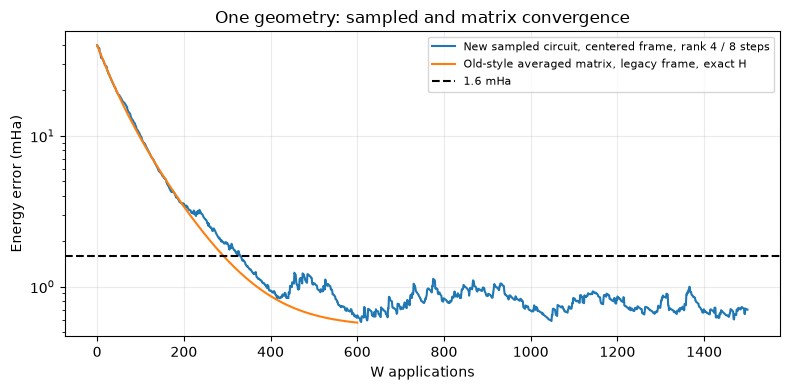

,run,final_error_mHa,W_applications
0,sampled circuit,0.702581,1500
1,old-style matrix average,0.576234,600


In [8]:
matrix_config=dict(accuracy_config,hamiltonian_simulation="exact_matrix",
    evolution_mode="averaged_matrix",filter_scale="spectral_width",w_convention="legacy",
    N_applications=600,energy_stride=1)
matrix_reference=rxn.run_reaction(matrix_config)
matrix_rows=pd.DataFrame(matrix_reference["energy_rows"])
matrix_rows["error_mHa"]=1000*(matrix_rows.energy-reference_energy)
assert matrix_rows.error_mHa.iloc[-1]<1.6
fig,ax=plt.subplots(figsize=(8,4))
ax.semilogy(accuracy_rows.step,accuracy_rows.error_mHa,label="New sampled circuit, centered frame, rank 4 / 8 steps")
ax.semilogy(matrix_rows.step,matrix_rows.error_mHa,label="Old-style averaged matrix, legacy frame, exact H")
ax.axhline(1.6,color="black",ls="--",label="1.6 mHa")
ax.set(xlabel="W applications",ylabel="Energy error (mHa)",title="One geometry: sampled and matrix convergence")
ax.legend(fontsize=8);ax.grid(alpha=.25);fig.tight_layout();plt.show()
display(pd.DataFrame({"run":["sampled circuit","old-style matrix average"],
    "final_error_mHa":[final_error,float(matrix_rows.error_mHa.iloc[-1])],
    "W_applications":[1500,600]}))

Reproduce the convergence run from the command line, without saved run artifacts:
```bash
python entire_rxn_with_circuit.py --convergence-example --logical-resources --save-outputs none
```
For inline reaction plots: `rxn.plot_results(accuracy)`. This verifies one geometry; it does not establish accuracy for every geometry along the full reaction.

## Contextual reduction and low-energy Trotter
Contextual reduction uses the thesis noncontextual generators and anticommuting representatives, then projects H, every jump and the carried state with the same isometry. Its coefficient-ordered subset is a heuristic; it releases constraints until the **energy tolerance** is met. The energy criterion does not bound dynamical error.

Low-energy Trotter leaves H and the jumps unchanged. It calibrates the Pauli product formula on the initial and jump-enlarged energy windows. This exact finite-instance calibration is exponential classical work, and its per-interval test is **not a certificate for the entire W trajectory**. The old low-rank method remains the default option. A reduced generic Pauli Hamiltonian must use `pauli` or `low_energy`, not the electronic low-rank decomposition.

Frame 111: 6 qubits, 2 W, 2 cached blocks, energy=-1.5220738560437272, 1.32 s


,retained_qubits,energy,error
0,0,-1.531077,3.992794e-02
1,1,-1.531077,3.992794e-02
2,2,-1.531077,3.992794e-02
3,3,-1.531077,3.992794e-02
4,4,-1.531077,3.992794e-02
5,5,-1.554008,1.699673e-02
6,6,-1.571005,1.998401e-15


method                      finite-instance restricted product-formula error
time                                                                -0.89585
steps                                                                      4
final_rank                                                                 4
initial_window_size                                                       14
jump_window_size                                                          20
initial_cutoff                                                     -0.457558
jump_cutoff                                                         0.353541
initial_width                                                       1.113447
jump_width                                                          1.924546
input_leakage_amplitude                                             0.052548
jump_leakage                                                             0.0
epsilon_state                                                            0.1

,steps,full,sector,initial_window,jump_window
0,1,0.020099,0.017421,0.016654,0.017421
1,2,0.004737,0.004150,0.003949,0.004150
2,4,0.001167,0.001026,0.000975,0.001026


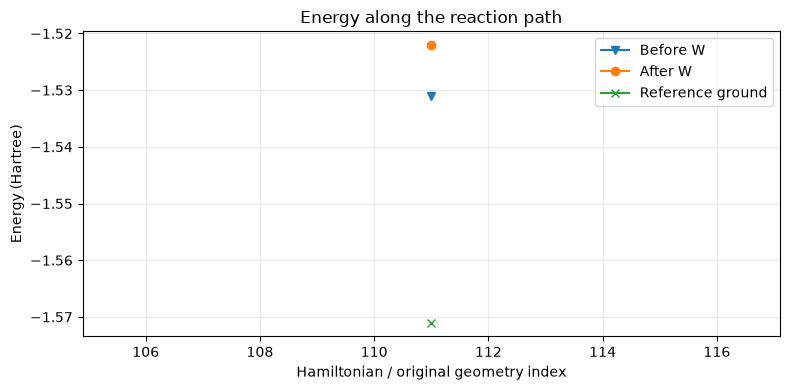

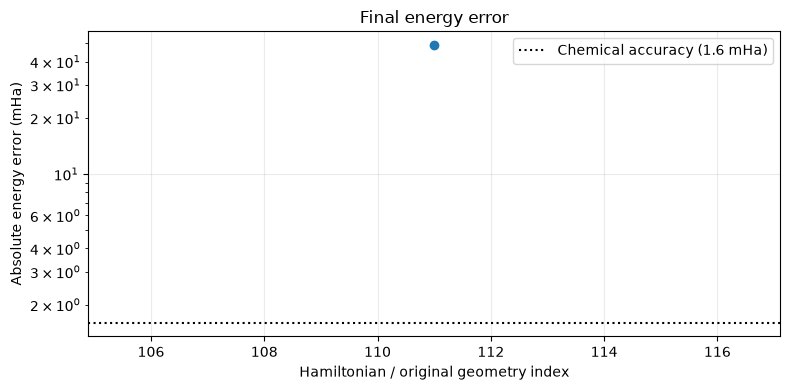

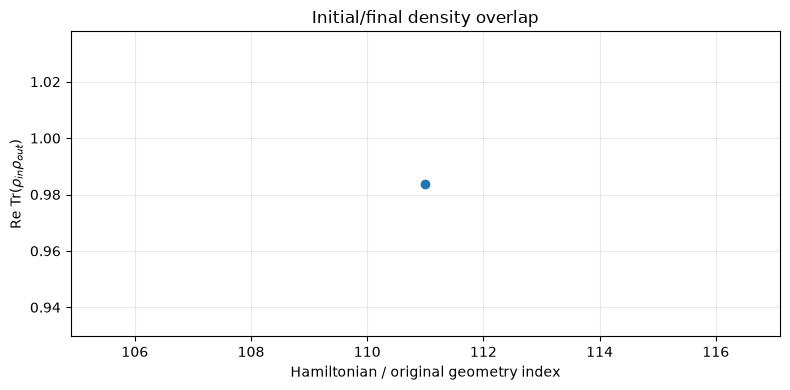

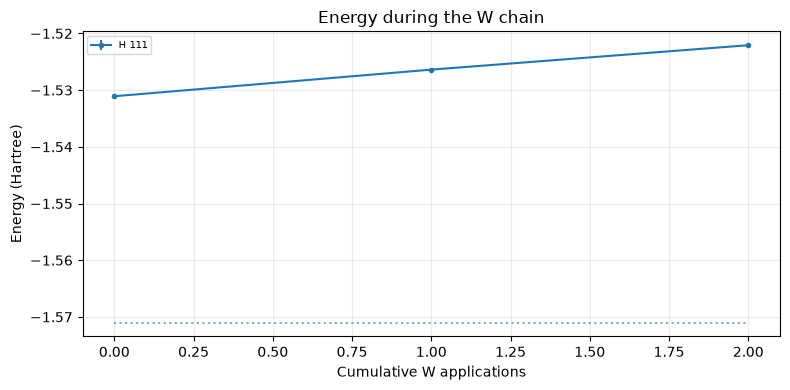

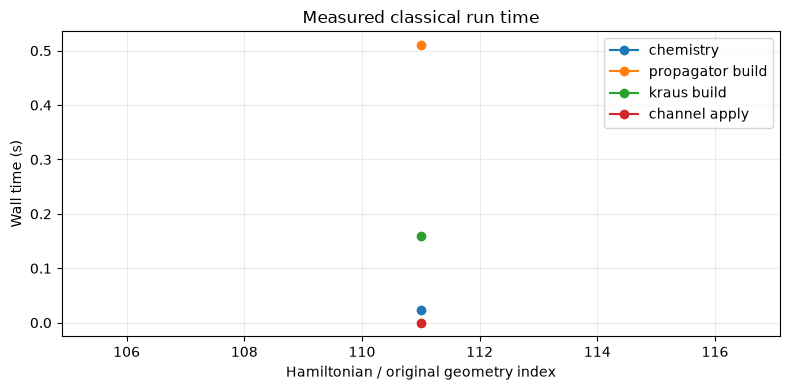

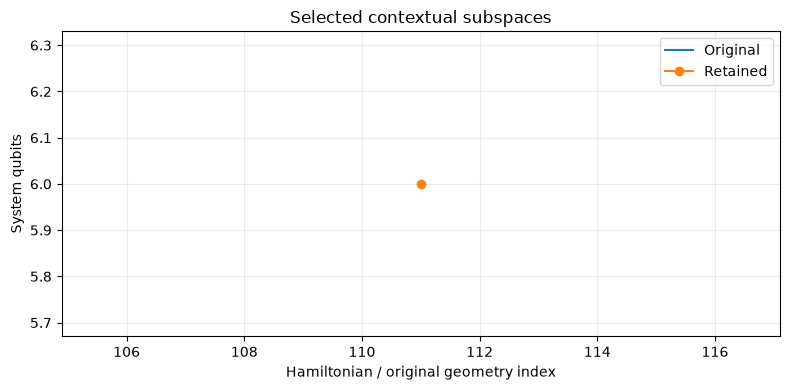

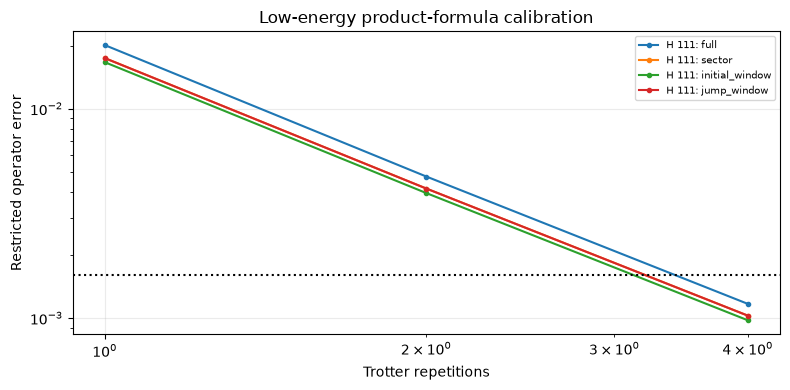

Toy projection check passed: 2 → 0 qubits


In [9]:
reduction_config = dict(one_config, contextual=True, hamiltonian_simulation="low_energy",
    filter_K=1, reps_per_W=1, N_applications=2)
reduced = rxn.run_reaction(reduction_config)
d = reduced["geometries"][0]["diagnostics"]
display(pd.DataFrame(d["contextual"]["candidates"]))
display(pd.Series({k:v for k,v in d["propagation"].items() if k!="error_scan"}, name="low-energy diagnostic"))
display(pd.DataFrame(d["propagation"]["error_scan"]))
reduced_figures = rxn.plot_results(reduced)
# H3 may correctly fall back to all six qubits at the strict energy tolerance.
# An independent two-qubit example checks a genuinely reduced operator map.
qs=tuple(cirq.LineQubit.range(1,3))
toy_h=cirq.PauliSum.wrap(.7*cirq.Z(qs[0])+.3*cirq.X(qs[1])+.2*cirq.Z(qs[1]))
toy_j=[Jump("X0",cirq.PauliSum.wrap(cirq.X(qs[0])))]
red=contextual.reduce_operators(toy_h,toy_j,qs,energy_tolerance=1e-10)
V=red.isometry()
assert np.allclose(V.conj().T@toy_h.matrix(qubits=qs)@V, red.hamiltonian.matrix(qubits=red.qubits))
assert np.allclose(V.conj().T@toy_j[0].operator.matrix(qubits=qs)@V, red.jumps[0].operator.matrix(qubits=red.qubits))
print("Toy projection check passed:", len(qs), "→", len(red.qubits), "qubits")

## Logical resources — pyLIQTR
Count the original low-rank sampled circuits above. Each unique block is visited once and multiplied by its actual repetition count. The **whole supplied sequence** shares one rotation-synthesis error budget. `T` is pyLIQTR's synthesis estimate, not an explicitly synthesized circuit or an analytic gate-count proxy.

Scope: unitary W blocks. State preparation, ancilla-reset implementation, energy-readout copies and contextual state projection/transport need separate hardware costs. Energy shots here sample independent copies and do not collapse the carried state. With `energy_shots=0`, energies are exact classical diagnostics and have no readout circuit cost included.

The input is a **mapping of distinct W blocks to sampled multiplicities**. The counter recursively profiles each unique subcircuit and each unique leaf operation once. It multiplies nested `CircuitOperation.repetitions` and jump multiplicities using integers. No full reaction circuit, repeated-gate list or flattened W circuit is constructed.

,LogicalQubits,T,Clifford,Rotations,native_T,circuit_precision,per_rotation_precision,unique_counted_blocks,scope,unique_profiled_operations,unique_W_blocks,W_applications,T_method
one W,7,293832,590905,4200,4032,0.001,0.0,5,unitary W sequence,159,1,1,pyLIQTR synthesis estimate; not an explicitly ...
one Hamiltonian,7,642348000,1289583793,6300000,6048000,0.001,0.0,121,unitary W sequence,275,30,1500,pyLIQTR synthesis estimate; not an explicitly ...
reaction segment,7,2653056,5331889,33600,32256,0.001,0.0,25,unitary W sequence,302,8,8,pyLIQTR synthesis estimate; not an explicitly ...


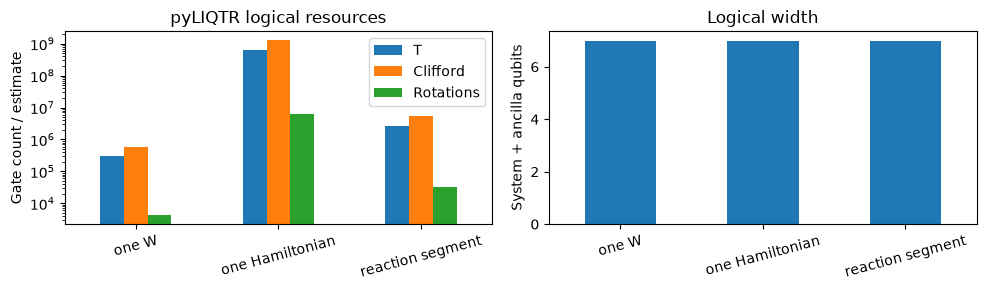

Ancilla resets required by the reaction channel: 8


In [10]:
one_W = factory.circuit(sequence[0])
one_hamiltonian_blocks = one_ham.selected_block_counts(factory,sequence)
logical = {}
for label,circuits in {"one W":{one_W:1}, "one Hamiltonian":one_hamiltonian_blocks,
                       "reaction segment":reaction_blocks}.items():
    logical[label] = one_ham.pyliqtr_resources(circuits, circuit_precision=1e-3)
logical_table=pd.DataFrame(logical).T
display(logical_table)
fig,axes=plt.subplots(1,2,figsize=(10,3))
logical_table[["T","Clifford","Rotations"]].astype(float).plot.bar(ax=axes[0],logy=True,rot=15)
axes[0].set(ylabel="Gate count / estimate",title="pyLIQTR logical resources")
logical_table["LogicalQubits"].astype(float).plot.bar(ax=axes[1],rot=15)
axes[1].set(ylabel="System + ancilla qubits",title="Logical width")
fig.tight_layout();plt.show()
print("Ancilla resets required by the reaction channel:", sum(reaction_blocks.values()))

### Counting optimization regression
The first check compares two equivalent tiny inputs. The second represents **one trillion rotations** with only three unique leaf operations. It verifies that the count scales with multiplicity while the stored/countable circuit remains small. This is a synthetic counting test, not a molecular resource result.

In [11]:
from time import perf_counter
import tracemalloc
# Make the actual sampled multiplicities reviewable.
frequency_rows=[]
for g in reaction["geometries"]:
    for index,multiplicity in Counter(g["chain"]["sequence"]).items():
        frequency_rows.append({"frame":g["frame_index"],"jump":g["factory"].jumps[index].name,
                               "W multiplicity":multiplicity})
display(pd.DataFrame(frequency_rows))
q=cirq.LineQubit.range(2)
tiny=cirq.FrozenCircuit(cirq.H(q[0]),cirq.CNOT(*q),cirq.rz(.123)(q[1]))
weighted=one_ham.pyliqtr_resources({tiny:7})
flat_tiny=one_ham.pyliqtr_resources([cirq.Circuit(tiny*7)])  # 21 gates only, test reference
assert all(weighted[k]==flat_tiny[k] for k in ("T","Clifford","Rotations","LogicalQubits"))
# repeat() stores an integer in a CircuitOperation; it does not duplicate gates.
huge_reference=cirq.FrozenCircuit(cirq.CircuitOperation(tiny).repeat(1_000_000))
tracemalloc.start();start=perf_counter()
huge_counts=one_ham.pyliqtr_resources({huge_reference:1_000_000})
elapsed=perf_counter()-start
_,peak=tracemalloc.get_traced_memory();tracemalloc.stop()
assert huge_counts["Rotations"]==10**12
assert huge_counts["unique_profiled_operations"]==3
assert huge_counts["unique_counted_blocks"]==2
display(pd.Series({"Represented rotations":huge_counts["Rotations"],
    "Unique profiled operations":huge_counts["unique_profiled_operations"],
    "Unique counted blocks":huge_counts["unique_counted_blocks"],
    "Count time (s)":elapsed,"Peak traced allocation (MiB)":peak/2**20},
    name="No-expansion regression"))

,frame,jump,W multiplicity
0,111,"Ax:[(2, 4)]",1
1,111,"Ay:[(2, 5)]",1
2,111,"Ay:[(3, 4)]",1
3,111,"Ax:[(0, 1)]",1
4,112,"Ay:[(2, 5)]",1
5,112,"Ay:[(3, 4)]",1
6,112,"Ax:[(0, 1)]",1
7,112,"Ay:[(0, 1)]",1


Represented rotations           1.000000e+12
Unique profiled operations      3.000000e+00
Unique counted blocks           2.000000e+00
Count time (s)                  3.170830e-04
Peak traced allocation (MiB)    1.577187e-02
Name: No-expansion regression, dtype: float64

## HPC: same functions, larger configuration
Edit `USER_CONFIG` in `entire_rxn_with_circuit.py`, or supply a JSON config. The same tables and plots are returned by `run_reaction` / `plot_results`; there is no notebook-only physics implementation.

```python
large = dict(rxn.USER_CONFIG,
    xyz_trajectory="reaction_data/Metal-ion/battery_MEP_trj.xyz",
    geometry_start=0, geometry_stop=2,
    charge=0, multiplicity=1,  # replace with the validated molecular specification
    n_active_electrons=12, n_active_orbitals=10,
    simulate=False, spectral_method="bound",
    logical_resources=True, save_outputs="none")
# result = rxn.run_reaction(large)
# figures = rxn.plot_results(result)
```

This example only illustrates the configuration format; validate the molecule, charge, spin and active orbitals before a production run. Build/resource mode scales beyond the dense simulator and gives resource/timing outputs. **It cannot produce energy or density-overlap plots without a state simulation.** This driver also materializes the original-space reference and contextual state isometry during energy runs. Its dense guard therefore applies to the original qubit count as well as the effective space; contextual circuit reduction alone does not make a large energy simulation scalable. Do not remove the guard merely to make a plot appear.

Command-line smoke test, no saved run artifacts:
```bash
python entire_rxn_with_circuit.py --small-example --logical-resources --save-outputs none
```
In a notebook, `rxn.plot_results(result)` displays figures inline. A headless batch job prints the tables; use an HPC Jupyter session for inline figures, or explicitly opt into saved outputs.

When `logical_resources=True`, `result["logical_total"]` gives the whole-reaction count with one shared synthesis-error budget. Per-geometry rows have their own stated budget and must not be summed to infer that total.